# Student Performance Predictor

## Project Objective

The goal of this project is to explore student performance data and build machine learning models that predict a student's final mathematics grade.

This project will:
1. Load and inspect the dataset.
2. Explore relationships between student characteristics and grades.
3. Prepare the data for machine learning.
4. Train and compare two regression models.
5. Evaluate prediction accuracy.
6. Investigate important features and discuss limitations.

## Dataset

Source: UCI Machine Learning Repository — Student Performance dataset.

The target variable is `G3`, representing the final mathematics grade on a scale from 0 to 20.

This project investigates predictive relationships in the dataset. It does not attempt to establish that any particular factor causes a change in academic performance.

In [1]:
# Init and inital prints
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

sns.set_theme(style="whitegrid")

df = pd.read_csv("student-mat.csv", sep=";")

print("Dataset loaded successfully!")
print("Number of students:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Number of students: 395
Number of columns: 33


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [2]:
# Dataset Inspection
print("Dataset dimensions:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nFirst five rows:")
display(df.head())

print("\nSummary statistics:")
display(df.describe())

Dataset dimensions:
(395, 33)

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reas

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10



Summary statistics:


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [3]:
# Data Quality/Completeness Check
print("Missing values per column:")
display(df.isnull().sum())

print("Number of duplicate rows:", df.duplicated().sum())

print("\nFinal grade statistics:")
print(df["G3"].describe())

Missing values per column:


school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Number of duplicate rows: 0

Final grade statistics:
count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64


## Exploratory Data Analysis

Before training a model, first we must examine the distribution of final grades and investigate relationships between student characteristics and academic performance.

These visualizations help us understand the dataset and identify patterns worth investigating.

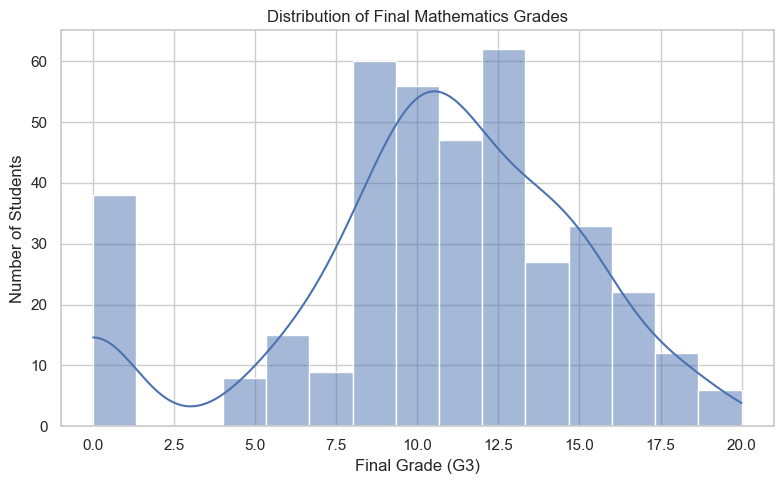

In [4]:
# Distribution of Final Grades
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="G3", bins=15, kde=True)

plt.title("Distribution of Final Mathematics Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

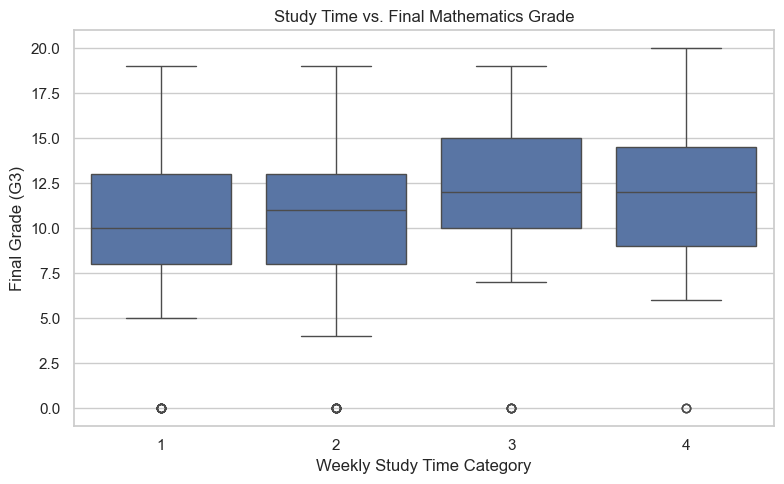

In [5]:
# Study Time vs Final Grades
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="studytime", y="G3")

plt.title("Study Time vs. Final Mathematics Grade")
plt.xlabel("Weekly Study Time Category")
plt.ylabel("Final Grade (G3)")
plt.tight_layout()
plt.show()

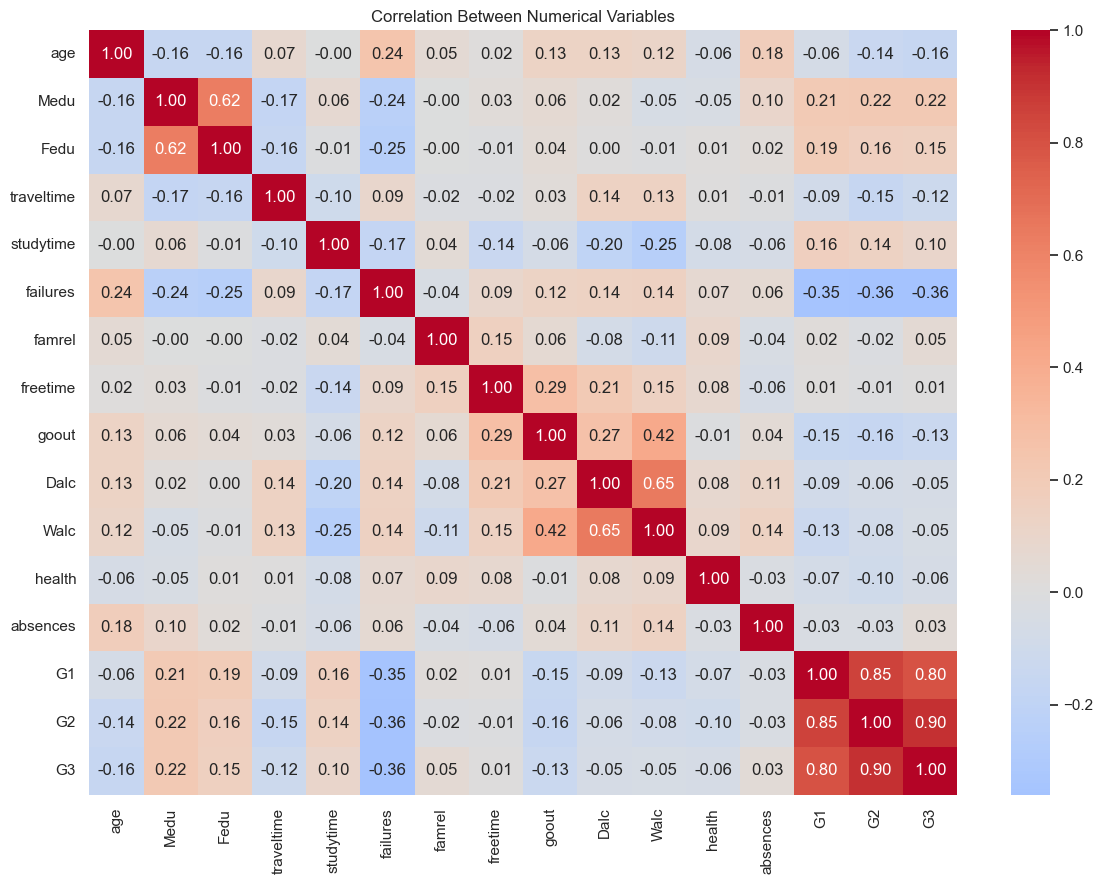

In [6]:
# Correlation Heatmap
numeric_df = df.select_dtypes(include="number")
correlation = numeric_df.corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()

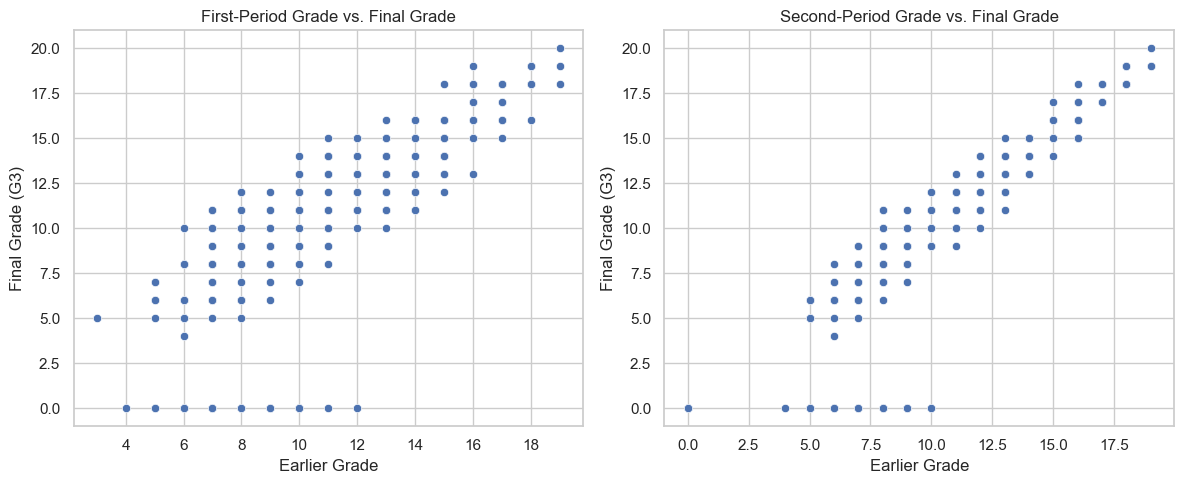

In [7]:
# Investigation of Earlier Grades
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(data=df, x="G1", y="G3", ax=axes[0])
axes[0].set_title("First-Period Grade vs. Final Grade")

sns.scatterplot(data=df, x="G2", y="G3", ax=axes[1])
axes[1].set_title("Second-Period Grade vs. Final Grade")

for ax in axes:
    ax.set_xlabel("Earlier Grade")
    ax.set_ylabel("Final Grade (G3)")

plt.tight_layout()
plt.show()

## Exploratory Data Analysis Findings

1. **Grade distribution:** The final grades appear to peak around the 7.5-12.5 area. The highest correlation of students to grade is around 10.

2. **Study time:** Students in the higher study-time categories appear to have the potential grades in category 4, but category 3 seems to have the highest average.

3. **Earlier grades:** The relationship between G1/G2 and G3 appears to be .80 and .90 respectively. G2 appears more close.

4. **Potential limitations:** These relationships show associations, not necessarily causal effects. Other factors may also influence student performance.

## Data Preparation

The final grade, `G3`, is predicted using the remaining student features.

Categorical variables must be converted into numerical representations before they can be used by our models.

Divide the data into training and testing sets. The training set is used to fit the models, while the test set is reserved for evaluating predictions on unseen observations.

In [8]:
# Defining of Features and Target

# Features: all columns except the final grade
X = df.drop(columns=["G3"])

# Target: final mathematics grade
y = df["G3"]

# Convert categorical features into numerical indicator columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Number of input features:", X.shape[1])
print("Number of target values:", y.shape[0])

display(X.head())

Number of input features: 41
Number of target values: 395


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,guardian_mother,guardian_other,schoolsup_yes,famsup_yes,paid_yes,activities_yes,nursery_yes,higher_yes,internet_yes,romantic_yes
0,18,4,4,2,2,0,4,3,4,1,...,1,0,1,0,0,0,1,1,0,0
1,17,1,1,1,2,0,5,3,3,1,...,0,0,0,1,0,0,0,1,1,0
2,15,1,1,1,2,3,4,3,2,2,...,1,0,1,0,1,0,1,1,1,0
3,15,4,2,1,3,0,3,2,2,1,...,1,0,0,1,1,1,1,1,1,1
4,16,3,3,1,2,0,4,3,2,1,...,0,0,0,1,1,0,1,1,0,0


In [9]:
# Splitting X and Y into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Total observations:", len(X_train) + len(X_test))

Training observations: 316
Testing observations: 79
Total observations: 395


## Model Training

We will compare two regression algorithms:

1. **Linear Regression:** A simple model that estimates a linear relationship between the input features and the final grade.
2. **Random Forest Regression:** An ensemble of decision trees that can learn more complex, nonlinear relationships.

Both models will use the same training and testing split so that their results can be compared fairly.

In [10]:
# Train and Evaluate both models

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    )
}

results = {}
predictions = {}

for name, model in models.items():
    # Train the model
    model.fit(X_train, y_train)

    # Predict grades for the test set
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    # Store the results
    results[name] = {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

    predictions[name] = y_pred

    print(f"\n{name}")
    print(f"MAE:  {mae:.3f}")
    print(f"RMSE: {rmse:.3f}")
    print(f"R²:   {r2:.3f}")


Linear Regression
MAE:  1.647
RMSE: 2.378
R²:   0.724

Random Forest
MAE:  1.173
RMSE: 1.967
R²:   0.811


In [11]:
# Compare model performance
results_df = pd.DataFrame(results).T

results_df.index.name = "Model"

display(results_df.round(3))

,MAE,RMSE,R2
Model,,,
Linear Regression,1.647,2.378,0.724
Random Forest,1.173,1.967,0.811


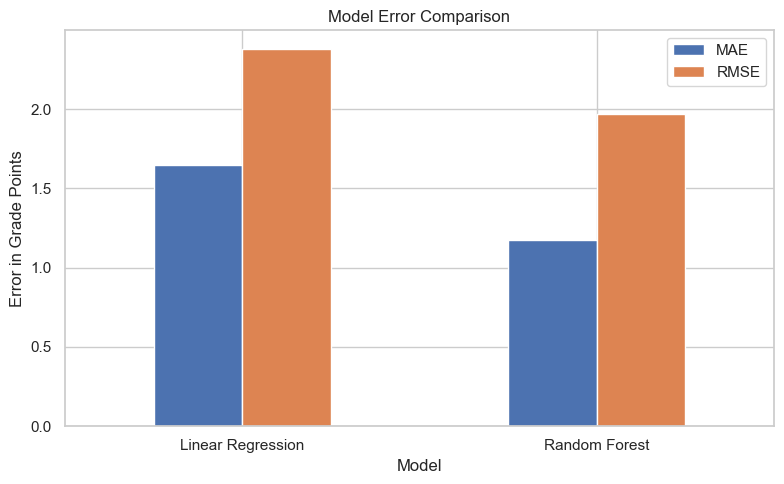

In [12]:
# Visualize the errors of the models
results_df[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Model Error Comparison")
plt.xlabel("Model")
plt.ylabel("Error in Grade Points")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
# Select the better of the two models
best_model_name = results_df["MAE"].idxmin()
best_model = models[best_model_name]
best_predictions = predictions[best_model_name]

print("Selected model:", best_model_name)
print(f"Test MAE: {results_df.loc[best_model_name, 'MAE']:.3f}")
print(f"Test RMSE: {results_df.loc[best_model_name, 'RMSE']:.3f}")
print(f"Test R²: {results_df.loc[best_model_name, 'R2']:.3f}")

Selected model: Random Forest
Test MAE: 1.173
Test RMSE: 1.967
Test R²: 0.811


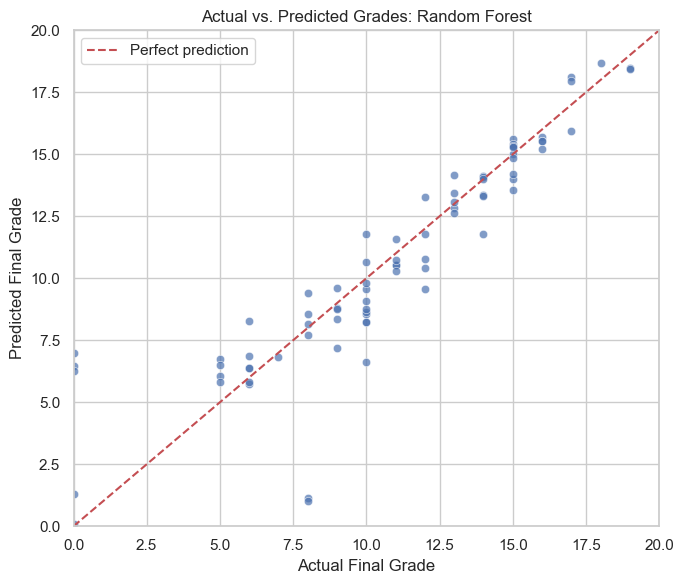

In [14]:
# Show actual grade vs predicted grade
plt.figure(figsize=(7, 6))

sns.scatterplot(
    x=y_test,
    y=best_predictions,
    alpha=0.7
)

# Reference line representing perfect predictions
plt.plot([0, 20], [0, 20], "r--", label="Perfect prediction")

plt.xlim(0, 20)
plt.ylim(0, 20)

plt.xlabel("Actual Final Grade")
plt.ylabel("Predicted Final Grade")
plt.title(f"Actual vs. Predicted Grades: {best_model_name}")

plt.legend()
plt.tight_layout()
plt.show()

In [15]:
# Examine prediction errors
error_df = pd.DataFrame({
    "Actual Grade": y_test,
    "Predicted Grade": best_predictions
})

error_df["Error"] = (
    error_df["Predicted Grade"] - error_df["Actual Grade"]
)

error_df["Absolute Error"] = error_df["Error"].abs()

display(error_df.head(10).round(2))

print("\nFive largest prediction errors:")
display(
    error_df.sort_values("Absolute Error", ascending=False)
    .head(5)
    .round(2)
)

,Actual Grade,Predicted Grade,Error,Absolute Error
78,10,8.24,-1.76,1.76
371,12,11.77,-0.23,0.23
248,5,6.72,1.72,1.72
55,10,9.56,-0.44,0.44
390,9,8.82,-0.18,0.18
223,13,12.85,-0.15,0.15
42,18,18.68,0.68,0.68
234,6,6.86,0.86,0.86
316,0,7.00,7.00,7.00
116,14,13.34,-0.65,0.65



Five largest prediction errors:


,Actual Grade,Predicted Grade,Error,Absolute Error
316,0,7.00,7.00,7.00
90,8,1.00,-7.00,7.00
124,8,1.12,-6.88,6.88
334,0,6.45,6.45,6.45
140,0,6.27,6.27,6.27


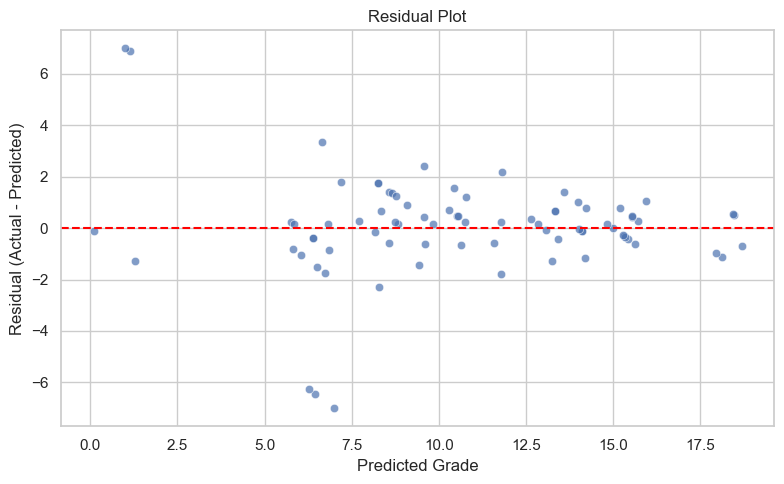

In [16]:
# Visualize the residuals
residuals = y_test - best_predictions

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=best_predictions,
    y=residuals,
    alpha=0.7
)

plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Predicted Grade")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot")
plt.tight_layout()
plt.show()

Top 10 features:


,Importance
G2,0.788004
absences,0.114189
reason_home,0.019827
age,0.009574
G1,0.005851
famrel,0.005042
health,0.004425
goout,0.004332
schoolsup_yes,0.004255
romantic_yes,0.003987


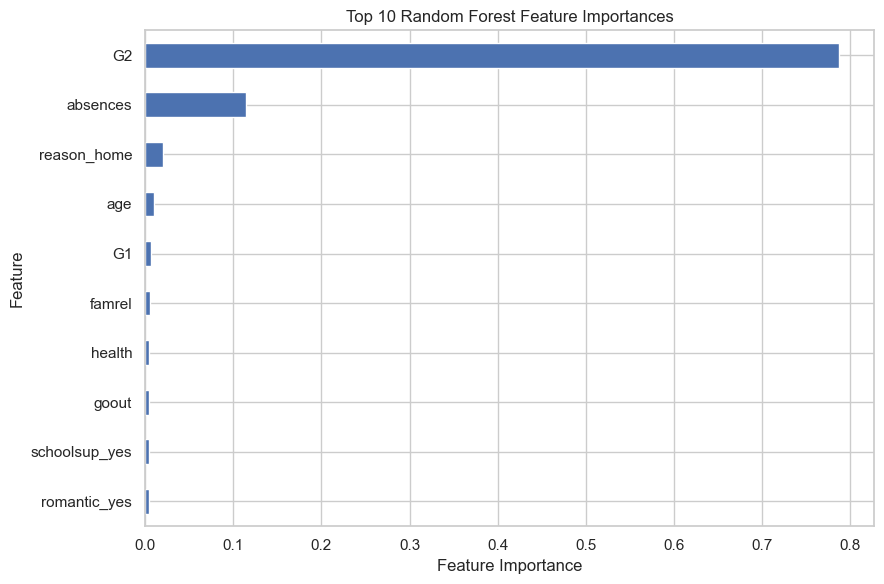

In [17]:
# Random forest feature importance
rf_model = models["Random Forest"]

importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Top 10 features:")
display(importance.head(10).to_frame("Importance"))

plt.figure(figsize=(9, 6))

importance.head(10).sort_values().plot(kind="barh")

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Random Forest Feature Importances")
plt.tight_layout()
plt.show()

## Feature Importance Findings

The random forest feature-importance analysis identifies which input features were most useful to the model.

The most important feature in my experiment was G2 with around 78.8% of the model's total feature importance, while G1 accounted for only about 0.58%. G2 provided substantially more predictive information about the final grade G3 than G1 did. The second most important feature, absenses, contributed 11.4%, while the other featured contributed a neglegible amount.

One possible explanation for this emphasis on G2 is that because G2 better reflected more recent academic performance than G1, therefore model was trained more heavily off of it, hence its importance.

However, feature importance measures predictive usefulness rather than causation. The results may also be influenced by correlations between features and the inclusion of earlier grades.

# Conclusion

## Project Summary

In this project, I explored the UCI Student Performance dataset and trained machine learning models to predict students' final mathematics grades.

## Main Findings

- **Data exploration:** My analysis suggested that the earlier period grades of G1 and G2 appeared to be solid indications of final grade performance among students, particularly with G2. Additionally, it appeared to show a direct correlation between proper studying and an average increase to a student's grade. Though studying seemed to increase a student's final grade potential, some students who studied more than others appeared to get lower grades despite this. Overall, while correlation does not argue causation, there seemed to be a solid relation between previous grades, studying, and the final grades that students recieved.
- **Model comparison:** The model with the lower test MAE was Random Forest, with an MAE of 1.173 compared to 1.647 for Linear Regression.
- **Prediction performance:** The selected model achieved an MAE of 1.173 grade points and an R² of 0.811, meaning it explained approximately 81.1% of the variation in final grades on the test dataset.
- **Feature importance:** The most important features in the random forest were G2 (second-period grade) and absences, with importance scores of approximately 0.788 and 0.114, respectively.

## Limitations

The dataset contains a limited number of students and may not represent all schools or student populations, only a small subset used as an example. The test results depend on the particular train/test split.

The model identifies predictive relationships, not causal effects. Its predictions should not be used to make consequential decisions about individual students. Only so much can be gathered from pure data points, and it is important to acknowledge the data, but not to treat it as the only and final source of information on the topic.

## Future Improvements

Possible improvements include using cross-validation, comparing additional models, investigating prediction errors, and testing the model on other datasets.

I could also investigate how performance changes when earlier grades are unavailable.

## Relevant Skills

This project gave me practical experience with data cleaning, exploratory data analysis, visualization, regression, model evaluation, and interpreting machine learning results.